In [6]:
from datasets import load_dataset

ds = load_dataset(
    "stanfordnlp/imdb",
    data_files={"train": "plain_text/train-*"},
    split="train",
    verification_mode="no_checks",
)

In [7]:
ds

Dataset({
    features: ['text', 'label'],
    num_rows: 25000
})

### Step 1: Preprocessing & Exploratory Data Analysis (EDA)
We will now clean the dataset, analyze length distributions, identify potential label leakage (explicit ratings), and create our stratified splits.

We use only the official training reviews during development. Labels are binary (0 = negative, 1 = positive); there is no neutral class. The unsupervised split is not used.

In [8]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42

# Keep the original row number to identify reviews later
train_df = pd.DataFrame(ds)
train_df['example_id'] = [f'train_{i:05d}' for i in range(len(train_df))]

print(f"Original train size: {len(train_df)}")

Original train size: 25000


In [9]:
train_df.head()

,text,label,example_id
0,I rented I AM CURIOUS-YELLOW from my video sto...,0,train_00000
1,"""I Am Curious: Yellow"" is a risible and preten...",0,train_00001
2,If only to avoid making this type of film in t...,0,train_00002
3,This film was probably inspired by Godard's Ma...,0,train_00003
4,"Oh, brother...after hearing about this ridicul...",0,train_00004


In [10]:
def clean_html(text):
    # Strip HTML tags like <br />
    return re.sub(r'<[^>]*>', ' ', text)

# 1. HTML Cleaning
train_df['cleaned_text'] = train_df['text'].apply(clean_html)

In [11]:
train_df.head()

,text,label,example_id,cleaned_text
0,I rented I AM CURIOUS-YELLOW from my video sto...,0,train_00000,I rented I AM CURIOUS-YELLOW from my video sto...
1,"""I Am Curious: Yellow"" is a risible and preten...",0,train_00001,"""I Am Curious: Yellow"" is a risible and preten..."
2,If only to avoid making this type of film in t...,0,train_00002,If only to avoid making this type of film in t...
3,This film was probably inspired by Godard's Ma...,0,train_00003,This film was probably inspired by Godard's Ma...
4,"Oh, brother...after hearing about this ridicul...",0,train_00004,"Oh, brother...after hearing about this ridicul..."


In [12]:
# 2. Normalize and Deduplicate
# Match exact duplicates after lowercasing and collapsing whitespace
# This does not detect paraphrases or other semantic near-duplicates
train_df['norm_text_for_dedup'] = (
    train_df['cleaned_text'].str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
)

before_dedup = len(train_df)
train_df = train_df.drop_duplicates(subset=['norm_text_for_dedup']).copy()
after_dedup = len(train_df)

print(f"Removed {before_dedup - after_dedup} duplicate reviews from the training set.")
print(f"New training set size: {after_dedup}")

Removed 98 duplicate reviews from the training set.
New training set size: 24902


In [13]:
# 3. Find Explicit Ratings
rating_pattern = r'\b\d{1,2}(?:\.\d+)?\s*(?:/|out\s+of)\s*10\b'

def find_explicit_ratings(text):
    return re.search(rating_pattern, text, re.IGNORECASE) is not None

train_df['has_explicit_rating'] = train_df['cleaned_text'].apply(find_explicit_ratings)
leakage_rate = train_df['has_explicit_rating'].mean() * 100

print(f"Reviews containing explicit ratings: {leakage_rate:.2f}%")
train_df.loc[train_df['has_explicit_rating'], ['text', 'label']].head(3)

Reviews containing explicit ratings: 8.70%


,text,label
3,This film was probably inspired by Godard's Ma...,0
19,Pros: Nothing<br /><br />Cons: Everything<br /...,0
21,1st watched 8/3/2003 - 2 out of 10(Dir-Brad Sy...,0


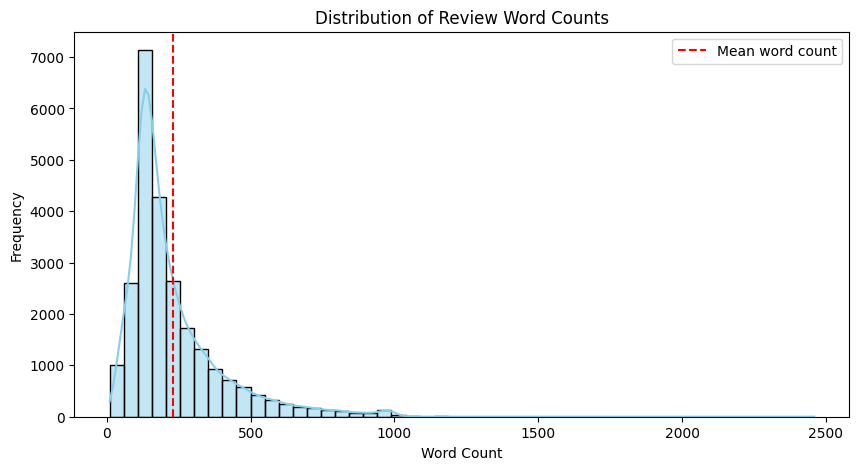

In [14]:
# 4. Length Analysis (Word Count distribution)
train_df['word_count'] = train_df['cleaned_text'].apply(lambda x: len(x.split()))

plt.figure(figsize=(10, 5))
sns.histplot(train_df['word_count'], bins=50, kde=True, color='skyblue')
plt.axvline(train_df['word_count'].mean(), color='red', linestyle='--', label='Mean word count')
plt.title('Distribution of Review Word Counts')
plt.xlabel('Word Count')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [15]:
print(f"Mean word count: {train_df['word_count'].mean():.1f}")
print(f"Median word count: {train_df['word_count'].median():.1f}")
print(f"Percentage of reviews exceeding 512 words: {(train_df['word_count'] > 512).mean() * 100:.2f}%")
print("Actual word-piece truncation rates will be measured with the DistilBERT tokenizer.")

Mean word count: 231.7
Median word count: 173.0
Percentage of reviews exceeding 512 words: 7.45%
Actual word-piece truncation rates will be measured with the DistilBERT tokenizer.


We will keep 5,000 reviews for development, with the same class balance as the training set. Using seed 42 gives us the same split each time.

In [16]:
# 5. Create a Stratified Train/Dev Split
from sklearn.model_selection import train_test_split

dev_df, train_split_df = train_test_split(
    train_df,
    train_size=5000,
    stratify=train_df['label'],
    random_state=SEED
)
train_split_df = train_split_df.reset_index(drop=True)
dev_df = dev_df.reset_index(drop=True)

In [17]:
print(f"Train reviews: {len(train_split_df)}")
print(f"Dev reviews: {len(dev_df)}")
dev_df['label'].value_counts()

Train reviews: 19902
Dev reviews: 5000


,count
label,
1,2504
0,2496


### Step 2: TF-IDF Features
We will now turn the reviews into numerical features. We use single words and pairs of words, keeping stopwords so phrases like "not good" are retained. The vocabulary is learned from training reviews only.

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

In [19]:
X_train = vectorizer.fit_transform(train_split_df['cleaned_text'])
X_dev = vectorizer.transform(dev_df['cleaned_text'])

y_train = train_split_df['label']
y_dev = dev_df['label']

print(f"Training feature matrix: {X_train.shape}")
print(f"Dev feature matrix: {X_dev.shape}")

Training feature matrix: (19902, 364489)
Dev feature matrix: (5000, 364489)


### Step 3: Baseline Models
Let's start with Logistic Regression and try three values of C. We choose the one with the highest dev accuracy and also report macro-F1. A small helper keeps the scoring the same for each model.

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score

predictions = {}
scores = []

In [21]:
def evaluate_model(model, X, name):
    pred = model.predict(X)
    predictions[name] = dev_df[['example_id', 'label']].assign(
        model=name, pred=pred, prob=model.predict_proba(X)[:, 1]
    )
    scores.append({
        'model': name,
        'accuracy': accuracy_score(y_dev, pred),
        'macro_f1': f1_score(y_dev, pred, average='macro')
    })

In [22]:
# 1. Compare Three Values of C
lr_models = {}
for C in [0.1, 1, 10]:
    name = f'lr_C_{C:g}'
    model = LogisticRegression(C=C, max_iter=1000, random_state=SEED)
    model.fit(X_train, y_train)
    lr_models[name] = model
    evaluate_model(model, X_dev, name)

In [23]:
# A tie keeps the smaller C, since we tried values in ascending order
lr_results = pd.DataFrame(scores).sort_values('accuracy', ascending=False, kind='stable')
best_lr_name = lr_results.iloc[0]['model']
best_lr = lr_models[best_lr_name]
best_C = best_lr.C

print(f"Selected C: {best_C}")
lr_results

Selected C: 10


,model,accuracy,macro_f1
2,lr_C_10,0.9012,0.901198
1,lr_C_1,0.8890,0.888980
0,lr_C_0.1,0.8592,0.859113


Naive Bayes gives us a second, quick baseline. We can reuse the same TF-IDF features.

In [24]:
# 2. Train Naive Bayes
nb_model = MultinomialNB(alpha=1.0)
nb_model.fit(X_train, y_train)

evaluate_model(nb_model, X_dev, 'naive_bayes')
pd.DataFrame(scores)

,model,accuracy,macro_f1
0,lr_C_0.1,0.8592,0.859113
1,lr_C_1,0.8890,0.888980
2,lr_C_10,0.9012,0.901198
3,naive_bayes,0.8828,0.882774


### Step 4: Does Preprocessing Make a Difference?
We will now change one thing at a time, keeping the same split and selected C. First, does removing ratings such as "8/10" affect the result?

In [25]:
# 1. Remove Explicit Ratings from Both Sets
def remove_explicit_ratings(text):
    return re.sub(rating_pattern, ' ', text, flags=re.IGNORECASE)

train_no_ratings = train_split_df['cleaned_text'].apply(remove_explicit_ratings)
dev_no_ratings = dev_df['cleaned_text'].apply(remove_explicit_ratings)

In [26]:
# Fit a fresh vocabulary after removing the ratings
rating_vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_ratings = rating_vectorizer.fit_transform(train_no_ratings)
X_dev_ratings = rating_vectorizer.transform(dev_no_ratings)

In [27]:
rating_model = LogisticRegression(C=best_C, max_iter=1000, random_state=SEED)
rating_model.fit(X_train_ratings, y_train)

evaluate_model(rating_model, X_dev_ratings, 'lr_no_ratings')
pd.DataFrame(scores).tail(1)

,model,accuracy,macro_f1
4,lr_no_ratings,0.9012,0.9012


Next, let's remove English stopwords. This also removes words like "not", which could change the meaning of a review.

In [28]:
# 2. Try Stopword Removal on the Original Cleaned Text
stopword_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words='english'
)
X_train_stopwords = stopword_vectorizer.fit_transform(train_split_df['cleaned_text'])
X_dev_stopwords = stopword_vectorizer.transform(dev_df['cleaned_text'])

In [29]:
stopword_model = LogisticRegression(C=best_C, max_iter=1000, random_state=SEED)
stopword_model.fit(X_train_stopwords, y_train)

evaluate_model(stopword_model, X_dev_stopwords, 'lr_stopwords')

In [30]:
# Compare all runs
results_df = pd.DataFrame(scores)
results_df

,model,accuracy,macro_f1
0,lr_C_0.1,0.8592,0.859113
1,lr_C_1,0.8890,0.888980
2,lr_C_10,0.9012,0.901198
3,naive_bayes,0.8828,0.882774
4,lr_no_ratings,0.9012,0.901200
5,lr_stopwords,0.8936,0.893589


In the first run, C = 10 gave 90.12% dev accuracy. Removing numeric ratings gave the same accuracy, while removing stopwords reduced it to 89.36%. We will keep stopwords for now. The rating check only covers the expressions matched by our regex.

### Step 5: A Closer Look at the Predictions
Overall accuracy does not show which class is harder. Let's compare precision, recall and the confusion matrices for our two baselines.

In [31]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

lr_predictions = predictions[best_lr_name]
nb_predictions = predictions['naive_bayes']

print("Logistic Regression")
print(classification_report(y_dev, lr_predictions['pred'], target_names=['negative', 'positive']))

Logistic Regression
              precision    recall  f1-score   support

    negative       0.90      0.90      0.90      2496
    positive       0.90      0.90      0.90      2504

    accuracy                           0.90      5000
   macro avg       0.90      0.90      0.90      5000
weighted avg       0.90      0.90      0.90      5000



In [32]:
print("Naive Bayes")
print(classification_report(y_dev, nb_predictions['pred'], target_names=['negative', 'positive']))

Naive Bayes
              precision    recall  f1-score   support

    negative       0.87      0.90      0.88      2496
    positive       0.90      0.87      0.88      2504

    accuracy                           0.88      5000
   macro avg       0.88      0.88      0.88      5000
weighted avg       0.88      0.88      0.88      5000



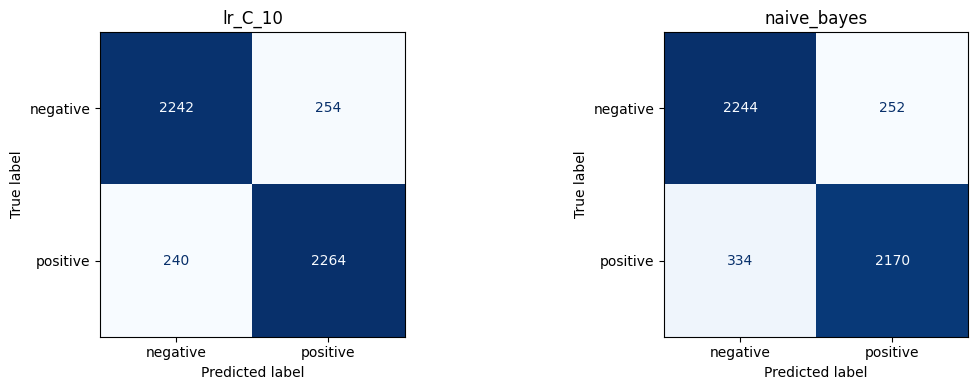

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, [best_lr_name, 'naive_bayes']):
    ConfusionMatrixDisplay.from_predictions(
        y_dev, predictions[name]['pred'], ax=ax,
        display_labels=['negative', 'positive'], cmap='Blues', colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

Are more confident predictions more often correct? Here, `prob` is the probability of a positive review, so confidence in the predicted class is the larger of `prob` and `1 - prob`.

In [34]:
confidence = pd.concat([lr_predictions, nb_predictions], ignore_index=True)
confidence['correct'] = confidence['pred'] == confidence['label']
confidence['confidence'] = np.maximum(confidence['prob'], 1 - confidence['prob'])
confidence['bucket'] = pd.cut(
    confidence['confidence'], bins=[0.5, 0.6, 0.7, 0.8, 0.9, 1.0], include_lowest=True
)

In [35]:
confidence_table = confidence.groupby(['model', 'bucket'], observed=False).agg(
    count=('correct', 'size'),
    accuracy=('correct', 'mean'),
    mean_confidence=('confidence', 'mean')
).reset_index()
confidence_table

,model,bucket,count,accuracy,mean_confidence
0,lr_C_10,"(0.499, 0.6]",397,0.564232,0.550505
1,lr_C_10,"(0.6, 0.7]",427,0.690867,0.651039
2,lr_C_10,"(0.7, 0.8]",552,0.817029,0.753329
3,lr_C_10,"(0.8, 0.9]",899,0.936596,0.854577
4,lr_C_10,"(0.9, 1.0]",2725,0.988624,0.964329
5,naive_bayes,"(0.499, 0.6]",789,0.623574,0.551871
6,naive_bayes,"(0.6, 0.7]",915,0.802186,0.654205
7,naive_bayes,"(0.7, 0.8]",1125,0.931556,0.752344
8,naive_bayes,"(0.8, 0.9]",1295,0.976834,0.850612
9,naive_bayes,"(0.9, 1.0]",876,0.998858,0.939849


Finally, let's read some mistakes. We sample 50 Logistic Regression errors for both reviewers to label independently. Possible causes include negation, contrast, sarcasm, plot description, mixed opinions, comparisons and long reviews.

In [36]:
errors = lr_predictions.loc[lr_predictions['pred'] != lr_predictions['label']]
error_sample = errors.sample(n=min(50, len(errors)), random_state=SEED)
error_sample = error_sample.merge(
    dev_df[['example_id', 'cleaned_text', 'word_count', 'has_explicit_rating']], on='example_id'
)

print(f"Logistic Regression errors: {len(errors)}")
error_sample[['label', 'pred', 'cleaned_text']].head()

Logistic Regression errors: 494


,label,pred,cleaned_text
0,1,0,"I'm a fan of C&C, going back to their records,..."
1,0,1,The 1930' were a golden age of Los Angeles wit...
2,1,0,Ask yourself where she got the gun? Remember w...
3,1,0,I have just finished watching this film and I ...
4,1,0,"Guns blasting, buildings exploding, cars crash..."


In [37]:
# Read one full review rather than just the shortened table preview
example = error_sample.iloc[0]
print(f"True label: {example['label']} | Predicted label: {example['pred']}")
print(example['cleaned_text'])

True label: 1 | Predicted label: 0
I'm a fan of C&C, going back to their records, and liked this movie, but at one point in the mid-1980's on cable television in San Jose California, it was aired with an alternate plot line that destroyed the entire point of the movie. All references to marijuana were replaced with "diamonds". The bag that "Red" drops to Chong has diamonds in it instead of marijuana, but the conversation still remains the same ("...it's worth ~$3000/lb"). There is also a subplot in which clips of aliens on a ship were added observing C&C, and talking to each other about getting the diamonds. At the end, instead of "space coke", it's something else. I'm not sure who created this version, but it was horrible, and obvious that they were attempting to make it family/child friendly. It would have been better if that network had not aired it at all.


### Step 6: DistilBERT
We will now fine-tune DistilBERT on the same training reviews. We keep the HTML cleaning and let its own tokenizer handle the text. Unlike TF-IDF, this model has a limited input length.

This part needs PyTorch, Transformers and Accelerate, and is best run on a GPU. We start with 256 tokens, 2 epochs and a learning rate of 2e-5, as in the plan.

In Colab, select **Runtime > Change runtime type > GPU** and run the notebook from the top. If needed, install the packages first with `%pip install datasets transformers accelerate seaborn`. The full neural experiments are still to be run; the existing outputs cover the baselines.

In [38]:
import torch
from time import perf_counter
from datasets import Dataset
from scipy.special import softmax
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import Trainer, TrainingArguments, DataCollatorWithPadding, set_seed

model_name = 'distilbert/distilbert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(model_name)
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU (training will be slow)')

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tesla T4


First, how long are the reviews in word-pieces? We tokenize once without truncation so we can try different lengths later. The model also needs two special tokens, [CLS] and [SEP].

In [39]:
for frame in [train_split_df, dev_df]:
    frame['tokens'] = tokenizer(
        frame['cleaned_text'].tolist(), add_special_tokens=False, truncation=False, verbose=False
    )['input_ids']
    frame['token_count'] = frame['tokens'].apply(len) + 2

train_split_df['token_count'].describe()

,token_count
count,19902.000000
mean,298.236459
std,222.179926
min,13.000000
25%,161.000000
50%,222.000000
75%,362.000000
max,3047.000000


At 128 tokens, 87.9% of training reviews are truncated.
At 256 tokens, 41.1% of training reviews are truncated.
At 512 tokens, 13.5% of training reviews are truncated.


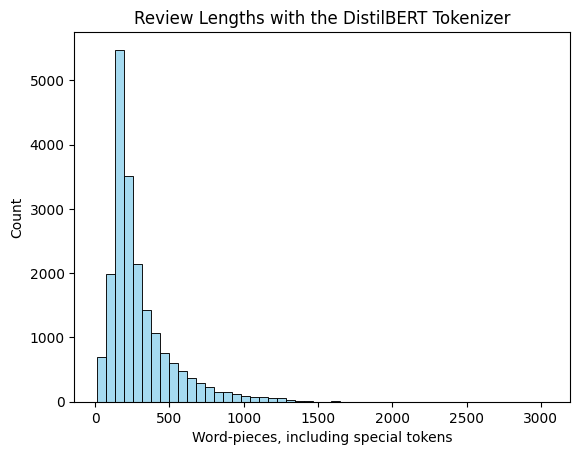

In [40]:
for length in [128, 256, 512]:
    truncated = (train_split_df['token_count'] > length).mean() * 100
    print(f"At {length} tokens, {truncated:.1f}% of training reviews are truncated.")

sns.histplot(train_split_df['token_count'], bins=50, color='skyblue')
plt.xlabel('Word-pieces, including special tokens')
plt.title('Review Lengths with the DistilBERT Tokenizer')
plt.show()

We will normally keep the start of a review. For the head+tail experiment, we keep equal amounts from the beginning and end. At a 256-token budget, this means 127 + 127 word-pieces plus the two special tokens. Short reviews are kept whole.

In [41]:
def trim_review(tokens, max_length, head_tail=False):
    budget = max_length - 2
    if head_tail and len(tokens) > budget:
        half = budget // 2
        tokens = tokens[:half] + tokens[-(budget - half):]
    else:
        tokens = tokens[:budget]
    return [tokenizer.cls_token_id] + tokens + [tokenizer.sep_token_id]

In [42]:
def make_dataset(frame, max_length, head_tail=False):
    input_ids = [trim_review(ids, max_length, head_tail) for ids in frame['tokens']]
    return Dataset.from_dict({'input_ids': input_ids, 'labels': frame['label'].tolist()})

# Pad only to the longest review in each batch
collator = DataCollatorWithPadding(tokenizer=tokenizer)
print(tokenizer.decode(trim_review(train_split_df.iloc[0]['tokens'], 128)))

[CLS] in conception a splendid film, investigating the tensions that occur in family life in the idyllic setting of galiano island off the coast of british columbia, _ the lotus eaters _ is marred by the fact that it has been packaged as a made - for - tv movie, diminishing itself throughout by the addition of chirpy music over potentially powerful scenes, as if to get ready for the interruption of commercials. a pity, really. [SEP]


To fit a 4 GB GPU, we use batches of 4 and accumulate gradients over four batches, giving an effective batch size of 16. Mixed precision and gradient checkpointing reduce memory use. We use AdamW with weight decay 0.01 and a linear learning-rate schedule, keeping these settings fixed across runs. These settings also work on a Colab GPU.

In [43]:
training_args = TrainingArguments(
    output_dir='.', num_train_epochs=2, learning_rate=2e-5,
    per_device_train_batch_size=4, gradient_accumulation_steps=4,
    per_device_eval_batch_size=8, optim='adamw_torch', weight_decay=0.01,
    lr_scheduler_type='linear', warmup_steps=0,
    fp16=torch.cuda.is_available(), gradient_checkpointing=True,
    seed=SEED, data_seed=SEED, dataloader_num_workers=0,
    save_strategy='no', logging_strategy='no', report_to='none', disable_tqdm=True
)

This helper starts from the original pretrained weights each time. We train for exactly two epochs, then predict on dev. Training time excludes downloading, tokenization and dev prediction.

In [44]:
def classification_loss(outputs, labels, num_items_in_batch=None):
    # Average over all reviews in the accumulated batch, including a partial batch
    loss = torch.nn.functional.cross_entropy(outputs.logits.float(), labels, reduction='sum')
    count = num_items_in_batch if num_items_in_batch is not None else labels.numel()
    return loss / count

In [45]:
def fit_distilbert(frame, max_length=256, head_tail=False):
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)
    trainer = Trainer(model=model, args=training_args, data_collator=collator,
                      train_dataset=make_dataset(frame, max_length, head_tail),
                      compute_loss_func=classification_loss)
    start = perf_counter()
    trainer.train()
    seconds = perf_counter() - start
    output = trainer.predict(make_dataset(dev_df, max_length, head_tail))
    prob = softmax(output.predictions, axis=1)[:, 1]
    model = model.cpu()
    del trainer
    torch.cuda.empty_cache()
    return model, prob, seconds

In [46]:
model_256, prob_256, seconds_256 = fit_distilbert(train_split_df)
print(f"Dev accuracy: {accuracy_score(y_dev, prob_256 >= 0.5):.4f}")
print(f"Training time: {seconds_256 / 60:.1f} minutes")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


KeyboardInterrupt: 

### Step 7: How Much of a Review Does the Model Need?
Experiment A compares 128, 256 and 512 tokens, plus head+tail at 256. We reuse the 256-token run above. All runs use the same reviews, seed and training settings.

In [ ]:
model_128, prob_128, seconds_128 = fit_distilbert(train_split_df, max_length=128)

In [ ]:
model_512, prob_512, seconds_512 = fit_distilbert(train_split_df, max_length=512)

In [ ]:
model_head_tail, prob_head_tail, seconds_head_tail = fit_distilbert(
    train_split_df, max_length=256, head_tail=True
)

In [ ]:
bert_probs = [prob_128, prob_256, prob_512, prob_head_tail]
length_results = pd.DataFrame({
    'setting': ['Head 128', 'Head 256', 'Head 512', 'Head+tail 256'],
    'max_length': [128, 256, 512, 256], 'head_tail': [False, False, False, True],
    'accuracy': [accuracy_score(y_dev, p >= 0.5) for p in bert_probs],
    'macro_f1': [f1_score(y_dev, p >= 0.5, average='macro') for p in bert_probs],
    'minutes': np.array([seconds_128, seconds_256, seconds_512, seconds_head_tail]) / 60
})
length_results

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
length_results.plot.bar(x='setting', y='accuracy', ax=axes[0], legend=False, color='skyblue')
length_results.plot.bar(x='setting', y='minutes', ax=axes[1], legend=False, color='lightgray')
axes[0].set_ylabel('Dev accuracy')
axes[1].set_ylabel('Training minutes')
for ax in axes:
    ax.tick_params(axis='x', rotation=25)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

We choose the best dev accuracy for the final comparison. If accuracies tie, we prefer the shorter input, then ordinary head truncation. Does the extra context seem worth its training cost?

In [ ]:
best_row = length_results.sort_values(
    ['accuracy', 'max_length', 'head_tail'], ascending=[False, True, True]
).iloc[0]
best_index = int(best_row.name)
best_bert = [model_128, model_256, model_512, model_head_tail][best_index]
best_bert_prob = bert_probs[best_index]
best_length = int(best_row['max_length'])
best_head_tail = bool(best_row['head_tail'])
print(f"Selected setting: {best_row['setting']}")

### Step 8: How Much Labelled Data Do We Need?
Experiment B compares 1,000, 5,000 and all 19,902 training reviews. The plan's 25,000 endpoint is reduced by deduplication and the dev holdout. We create nested, stratified subsets and give exactly the same reviews to both models.

C stays fixed at the value selected earlier. DistilBERT stays at 256 tokens and two epochs, so input length does not change along the learning curve. Each smaller neural model starts from the pretrained base model.

In [ ]:
train_5000, _ = train_test_split(
    train_split_df, train_size=5000, stratify=train_split_df['label'], random_state=SEED
)
train_1000, _ = train_test_split(
    train_5000, train_size=1000, stratify=train_5000['label'], random_state=SEED
)
print(train_1000['label'].value_counts())
print(train_5000['label'].value_counts())

In [ ]:
def fit_small_baseline(frame):
    start = perf_counter()
    tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    features = tfidf.fit_transform(frame['cleaned_text'])
    model = LogisticRegression(C=best_C, max_iter=1000, random_state=SEED)
    model.fit(features, frame['label'])
    seconds = perf_counter() - start
    prob = model.predict_proba(tfidf.transform(dev_df['cleaned_text']))[:, 1]
    return prob, seconds

In [ ]:
lr_prob_1000, lr_seconds_1000 = fit_small_baseline(train_1000)
lr_prob_5000, lr_seconds_5000 = fit_small_baseline(train_5000)
lr_prob_full, lr_seconds_full = fit_small_baseline(train_split_df)

In [ ]:
model_1000, prob_1000, seconds_1000 = fit_distilbert(train_1000)

In [ ]:
model_5000, prob_5000, seconds_5000 = fit_distilbert(train_5000)

In [ ]:
sizes = [1000, 5000, len(train_split_df)]
learning_curve = pd.DataFrame({
    'train_size': sizes * 2,
    'model': ['Logistic Regression'] * 3 + ['DistilBERT'] * 3,
    'accuracy': [accuracy_score(y_dev, p >= 0.5) for p in
                 [lr_prob_1000, lr_prob_5000, lr_prob_full, prob_1000, prob_5000, prob_256]],
    'minutes': np.array([lr_seconds_1000, lr_seconds_5000, lr_seconds_full,
                         seconds_1000, seconds_5000, seconds_256]) / 60
})
learning_curve

In [ ]:
sns.lineplot(data=learning_curve, x='train_size', y='accuracy', hue='model', marker='o')
plt.xlabel('Training reviews')
plt.ylabel('Dev accuracy')
plt.title('Accuracy as the Training Set Grows')
plt.show()

The three points show where a model leads at the sizes we tested; they do not locate an exact crossover. The training times also use different hardware: Logistic Regression runs on the CPU and DistilBERT on the GPU, when available. TF-IDF fitting is included in the baseline times.

### Step 9: Where Do the Models Fail?
We will now compare the selected DistilBERT model with Logistic Regression on dev. All predictions follow the same review order, so we can inspect cases where the models disagree.

In [ ]:
bert_predictions = dev_df[['example_id', 'label']].assign(
    model='DistilBERT', pred=(best_bert_prob >= 0.5).astype(int), prob=best_bert_prob
)
print(classification_report(y_dev, bert_predictions['pred'], target_names=['negative', 'positive']))

In [ ]:
comparison = dev_df[['example_id', 'label', 'cleaned_text', 'token_count']].copy()
comparison['lr_pred'] = lr_predictions['pred'].to_numpy()
comparison['bert_pred'] = bert_predictions['pred'].to_numpy()
comparison['lr_correct'] = comparison['lr_pred'] == comparison['label']
comparison['bert_correct'] = comparison['bert_pred'] == comparison['label']
comparison['truncated'] = comparison['token_count'] > best_length
comparison.groupby('truncated').agg(
    reviews=('label', 'size'), lr_accuracy=('lr_correct', 'mean'), bert_accuracy=('bert_correct', 'mean')
)

In [ ]:
disagreements = comparison.loc[comparison['lr_pred'] != comparison['bert_pred']]
print(f"The models disagree on {len(disagreements)} dev reviews.")
disagreements[['label', 'lr_pred', 'bert_pred', 'cleaned_text']].head()

Let's sample 50 errors from each model. Overlapping examples only need to be read once. Both reviewers should categorise this same set independently before discussing their choices.

In [ ]:
lr_errors = comparison.loc[~comparison['lr_correct']]
bert_errors = comparison.loc[~comparison['bert_correct']]
lr_sample = lr_errors.sample(n=min(50, len(lr_errors)), random_state=SEED)
bert_sample = bert_errors.sample(n=min(50, len(bert_errors)), random_state=SEED)
error_cases = pd.concat([lr_sample, bert_sample]).drop_duplicates('example_id')
error_cases = error_cases.set_index('example_id')
print(f"Unique reviews for annotation: {len(error_cases)}")
error_cases[['label', 'lr_pred', 'bert_pred', 'cleaned_text']].head()

In [ ]:
# Change this row number to read another sampled review
example = error_cases.iloc[0]
print(f"ID: {example.name} | True: {example['label']} | LR: {example['lr_pred']} | BERT: {example['bert_pred']}")
print(example['cleaned_text'])

Use one main category per review: **negation**, **contrast**, **sarcasm**, **plot**, **mixed**, **comparison**, **long review**, or **other**. For "long review", check that the missed context matters; length alone is not enough.

Fill the two dictionaries below independently, using `example_id: category` pairs. These labels must come from the reviewers. Empty dictionaries mean that annotation has not been completed.

In [ ]:
reviewer_a = {}
reviewer_b = {}

In [ ]:
annotations = error_cases[['label']].copy()
annotations['reviewer_a'] = annotations.index.map(reviewer_a)
annotations['reviewer_b'] = annotations.index.map(reviewer_b)
paired = annotations.dropna(subset=['reviewer_a', 'reviewer_b'])
print(f"Both reviewers have labelled {len(paired)} of {len(annotations)} cases.")
if len(paired):
    disagreement = (paired['reviewer_a'] != paired['reviewer_b']).mean()
    print(f"Disagreement rate: {disagreement:.1%}")
else:
    print('Complete the independent annotations before reporting a disagreement rate.')

After discussing disagreements, enter the agreed categories below. We can then count causes separately for each model's 50-error sample. Use a few fully read examples to explain these counts in the report.

In [ ]:
agreed_categories = {}
lr_categories = lr_sample['example_id'].map(agreed_categories).value_counts()
bert_categories = bert_sample['example_id'].map(agreed_categories).value_counts()
category_counts = pd.DataFrame({'Logistic Regression': lr_categories, 'DistilBERT': bert_categories})
category_counts.fillna(0).astype(int)

### Step 10: Confidence and Human Review
We will repeat the confidence check with DistilBERT. Are the confident mistakes different from the uncertain ones? These are still dev diagnostics, since we used dev to select our models.

In [ ]:
confidence = pd.concat([lr_predictions, bert_predictions], ignore_index=True)
confidence['correct'] = confidence['pred'] == confidence['label']
confidence['confidence'] = np.maximum(confidence['prob'], 1 - confidence['prob'])
confidence['bucket'] = pd.cut(
    confidence['confidence'], bins=[0.5, 0.6, 0.7, 0.8, 0.9, 1.0], include_lowest=True
)
confidence.groupby(['model', 'bucket'], observed=False).agg(
    reviews=('correct', 'size'), accuracy=('correct', 'mean'), mean_confidence=('confidence', 'mean')
)

As an optional check, what happens if we send the least confident reviews to a human? Coverage is the fraction we classify automatically. We select reviews by confidence only, then measure accuracy on that subset.

In [ ]:
coverage_rows = []
for name, group in confidence.groupby('model'):
    ranked = group.sort_values('confidence', ascending=False)
    for coverage in [1.0, 0.9, 0.7]:
        kept = ranked.iloc[:int(len(ranked) * coverage)]
        coverage_rows.append({'model': name, 'coverage': coverage,
                              'accuracy': kept['correct'].mean()})
pd.DataFrame(coverage_rows)

### Step 11: Final Test Evaluation
**Freeze point:** finish all dev comparisons before running this section. We now fix the selected C, preprocessing and DistilBERT truncation setting. We use the trained models as they are and evaluate the official test set once. After seeing these results, we should not change the models to improve the test score.

In [ ]:
print(f"Logistic Regression: C={best_C}, stopwords and ratings kept")
print(f"DistilBERT: {best_row['setting']}, two epochs on {len(train_split_df)} reviews")

test_ds = load_dataset('stanfordnlp/imdb', data_files={'test': 'plain_text/test-*'}, split='test')
test_df = pd.DataFrame(test_ds)
test_df['cleaned_text'] = test_df['text'].apply(clean_html)
test_df['tokens'] = tokenizer(
    test_df['cleaned_text'].tolist(), add_special_tokens=False, truncation=False, verbose=False
)['input_ids']
y_test = test_df['label'].to_numpy()

In [ ]:
lr_test_prob = best_lr.predict_proba(vectorizer.transform(test_df['cleaned_text']))[:, 1]
lr_test_pred = (lr_test_prob >= 0.5).astype(int)

In [ ]:
test_trainer = Trainer(model=best_bert, args=training_args, data_collator=collator)
test_output = test_trainer.predict(make_dataset(test_df, best_length, best_head_tail))
bert_test_prob = softmax(test_output.predictions, axis=1)[:, 1]
bert_test_pred = (bert_test_prob >= 0.5).astype(int)
best_bert.cpu()
del test_trainer
torch.cuda.empty_cache()

In [ ]:
test_predictions = {'Logistic Regression': lr_test_pred, 'DistilBERT': bert_test_pred}
test_results = pd.DataFrame([
    {'model': name, 'accuracy': accuracy_score(y_test, pred),
     'macro_f1': f1_score(y_test, pred, average='macro')}
    for name, pred in test_predictions.items()
])
test_results

In [ ]:
for name, pred in test_predictions.items():
    print(name)
    print(classification_report(y_test, pred, target_names=['negative', 'positive'], digits=4))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, pred) in zip(axes, test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, ax=ax, display_labels=['negative', 'positive'], cmap='Blues', colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

### Step 12: How Certain Is the Difference?
We bootstrap the test reviews 2,000 times to get 95% accuracy intervals. Each resample draws reviews with replacement. These intervals describe uncertainty from this test sample, not variation from retraining with different seeds.

In [ ]:
def accuracy_interval(y_true, pred):
    correct = np.asarray(y_true) == np.asarray(pred)
    rng = np.random.default_rng(SEED)
    bootstrap_scores = [rng.choice(correct, size=len(correct), replace=True).mean()
                        for _ in range(2000)]
    return np.percentile(bootstrap_scores, [2.5, 97.5])

intervals = [accuracy_interval(y_test, pred) for pred in test_predictions.values()]
test_results['ci_low'] = [interval[0] for interval in intervals]
test_results['ci_high'] = [interval[1] for interval in intervals]
test_results

The models classified the same reviews, so their errors are paired. McNemar's exact test compares the two kinds of disagreement: only LR is correct, or only DistilBERT is correct. We use a two-sided binomial test on these discordant pairs.

In [ ]:
from scipy.stats import binomtest

lr_correct = lr_test_pred == y_test
bert_correct = bert_test_pred == y_test
lr_only = int((lr_correct & ~bert_correct).sum())
bert_only = int((~lr_correct & bert_correct).sum())
discordant = lr_only + bert_only
p_value = binomtest(lr_only, discordant, p=0.5).pvalue if discordant else 1.0

print(f"Only LR correct: {lr_only} | Only DistilBERT correct: {bert_only}")
print(f"McNemar exact p-value: {p_value:.4g}")

In [ ]:
difference = accuracy_score(y_test, bert_test_pred) - accuracy_score(y_test, lr_test_pred)
print(f"DistilBERT minus LR test accuracy: {difference * 100:+.2f} percentage points")
if p_value < 0.05:
    print('The paired test gives evidence of different error rates at the 5% level.')
else:
    print('The paired test does not give clear evidence of different error rates at the 5% level.')